In [1]:
# Import libraries
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

print("Pandas:", pd.__version__)
print("DuckDB:", duckdb.__version__)

Pandas: 3.1.0
DuckDB: 1.4.5


In [2]:
# Connect to AWS S3
con = duckdb.connect()

con.execute("LOAD httpfs;")
con.execute("SET s3_region = 'us-east-2';")

print("DuckDB connection established.")
print("AWS S3 access configured.")

DuckDB connection established.
AWS S3 access configured.


In [3]:
# Locate the 30 days of Ethereum data
files = con.execute("""
    SELECT file
    FROM glob(
        's3://aws-public-blockchain/v1.0/eth/transactions/date=2026-10-*/part-*.parquet'
    )
    ORDER BY file
""").df()

files["date"] = pd.to_datetime(
    files["file"].str.extract(r"date=(\d{4}-\d{2}-\d{2})")[0]
)

files = files[
    (files["date"] >= "2026-10-01") &
    (files["date"] <= "2026-10-30")
].copy()

files = files.sort_values("date").reset_index(drop=True)

print("Number of daily files:", len(files))
print("First date:", files["date"].min())
print("Last date:", files["date"].max())

display(files.head())
display(files.tail())

Number of daily files: 30
First date: 2026-10-01 00:00:00
Last date: 2026-10-30 00:00:00


,file,date
0,s3://aws-public-blockchain/v1.0/eth/transactio...,2026-10-01
1,s3://aws-public-blockchain/v1.0/eth/transactio...,2026-10-02
2,s3://aws-public-blockchain/v1.0/eth/transactio...,2026-10-03
3,s3://aws-public-blockchain/v1.0/eth/transactio...,2026-10-04
4,s3://aws-public-blockchain/v1.0/eth/transactio...,2026-10-05


,file,date
25,s3://aws-public-blockchain/v1.0/eth/transactio...,2026-10-26
26,s3://aws-public-blockchain/v1.0/eth/transactio...,2026-10-27
27,s3://aws-public-blockchain/v1.0/eth/transactio...,2026-10-28
28,s3://aws-public-blockchain/v1.0/eth/transactio...,2026-10-29
29,s3://aws-public-blockchain/v1.0/eth/transactio...,2026-10-30


In [4]:
def analyze_daily_activity(file_path):

    query = f"""
        SELECT
            COUNT(*) AS total_transactions,
            COUNT(*) FILTER (WHERE receipt_status = 1) AS successful_transactions,
            COUNT(*) FILTER (WHERE receipt_status = 0) AS failed_transactions,
            COUNT(DISTINCT from_address) AS unique_senders
        FROM read_parquet('{file_path}')
    """

    return con.execute(query).fetchone()

In [20]:
test_result = analyze_daily_activity(test_file)

print(test_result)

(2036041, 2012854, 23187, 614194)


In [21]:
from pathlib import Path
import time
import pandas as pd

# Find the project folder
current_dir = Path.cwd()

if (current_dir / "CSVs").exists():
    project_dir = current_dir
elif (current_dir.parent / "CSVs").exists():
    project_dir = current_dir.parent
else:
    raise FileNotFoundError("Cannot find the project's CSVs folder.")

checkpoint_path = project_dir / "CSVs" / "ethereum_network_activity_checkpoint.csv"

# Start with the successful October 1 test
columns = [
    "date",
    "total_transactions",
    "successful_transactions",
    "failed_transactions",
    "unique_senders"
]

checkpoint = pd.DataFrame(
    [[
        files.iloc[0]["date"],
        *test_result
    ]],
    columns=columns
)

# Recover previous progress if a checkpoint already exists
if checkpoint_path.exists():
    previous = pd.read_csv(checkpoint_path, parse_dates=["date"])
    checkpoint = pd.concat(
        [previous, checkpoint],
        ignore_index=True
    ).drop_duplicates(subset="date", keep="last")

checkpoint.to_csv(checkpoint_path, index=False)

# Process remaining days
for i, row in files.iterrows():

    day = pd.to_datetime(row["date"]).date()

    if day in set(pd.to_datetime(checkpoint["date"]).dt.date):
        print(f"Skipping {day}: already completed.")
        continue

    print(f"Processing {day}...")

    success = False

    for attempt in range(1, 4):

        try:
            result = analyze_daily_activity(row["file"])

            new_row = pd.DataFrame(
                [[day, *result]],
                columns=columns
            )

            checkpoint = pd.concat(
                [checkpoint, new_row],
                ignore_index=True
            )

            checkpoint.to_csv(checkpoint_path, index=False)

            print(f"Completed {day}.")
            success = True
            break

        except Exception as e:
            print(f"Attempt {attempt} failed: {e}")

            if attempt < 3:
                time.sleep(10)

    if not success:
        print(f"Stopping at {day}. Progress has been saved.")
        break

# Display progress
checkpoint = checkpoint.sort_values("date").reset_index(drop=True)

print("Completed days:", len(checkpoint))
print("Checkpoint:", checkpoint_path)

display(checkpoint.tail())

Skipping 2026-10-01: already completed.
Processing 2026-10-02...
Completed 2026-10-02.
Processing 2026-10-03...
Completed 2026-10-03.
Processing 2026-10-04...
Completed 2026-10-04.
Processing 2026-10-05...
Completed 2026-10-05.
Processing 2026-10-06...
Completed 2026-10-06.
Processing 2026-10-07...
Completed 2026-10-07.
Processing 2026-10-08...
Attempt 1 failed: IO Error: Could not establish connection error for HTTP GET to 'https://aws-public-blockchain.s3.us-east-2.amazonaws.com/v1.0/eth/transactions/date%3D2026-10-08/part-00000-a9a3c7be-2fcb-41c4-bb4c-9f20fbc7e254-c000.snappy.parquet'
Attempt 2 failed: IO Error: Could not establish connection error for HTTP HEAD to 'https://aws-public-blockchain.s3.us-east-2.amazonaws.com/v1.0/eth/transactions/date%3D2026-10-08/part-00000-a9a3c7be-2fcb-41c4-bb4c-9f20fbc7e254-c000.snappy.parquet'

LINE 7:         FROM read_parquet('s3://aws-public-blockchain/v1.0/eth/transactions...
                     ^
Attempt 3 failed: IO Error: SSL connection fa

TypeError: Cannot compare Timestamp with datetime.date. Use ts == pd.Timestamp(date) or ts.date() == date instead.

In [23]:
# Replace the previous date-normalization cell
checkpoint = pd.read_csv(checkpoint_path)

checkpoint["date"] = pd.to_datetime(
    checkpoint["date"],
    format="mixed"
)

checkpoint = checkpoint.sort_values(
    "date"
).reset_index(drop=True)

print("Completed days:", len(checkpoint))
display(checkpoint)

Completed days: 7


,date,total_transactions,successful_transactions,failed_transactions,unique_senders
0,2026-10-01,2036041,2012854,23187,614194
1,2026-10-02,1875646,1852270,23376,503146
2,2026-10-03,1562292,1542458,19834,412076
3,2026-10-04,1526358,1507728,18630,386638
4,2026-10-05,1774270,1750955,23315,445014
5,2026-10-06,1957602,1934388,23214,543286
6,2026-10-07,1963594,1942178,21416,569053


In [24]:
# Resume the 30-day analysis
completed_dates = set(checkpoint["date"].dt.date)

for i, row in files.iterrows():

    day = pd.to_datetime(row["date"]).date()

    if day in completed_dates:
        print(f"Skipping {day}: already completed.")
        continue

    print(f"Processing {day}...")

    success = False

    for attempt in range(1, 4):
        try:
            result = analyze_daily_activity(row["file"])

            new_row = pd.DataFrame(
                [[pd.Timestamp(day), *result]],
                columns=columns
            )

            checkpoint = pd.concat(
                [checkpoint, new_row],
                ignore_index=True
            )

            checkpoint["date"] = pd.to_datetime(
                checkpoint["date"],
                format="mixed"
            )

            checkpoint = checkpoint.sort_values(
                "date"
            ).reset_index(drop=True)

            checkpoint.to_csv(checkpoint_path, index=False)

            completed_dates.add(day)
            print(f"Completed {day}.")
            success = True
            break

        except Exception as e:
            print(f"Attempt {attempt} failed: {e}")

            if attempt < 3:
                time.sleep(20)

    if not success:
        print(f"Stopped at {day}. Checkpoint saved.")
        break

print("\nTotal completed days:", len(checkpoint))
display(checkpoint.tail())

Skipping 2026-10-01: already completed.
Skipping 2026-10-02: already completed.
Skipping 2026-10-03: already completed.
Skipping 2026-10-04: already completed.
Skipping 2026-10-05: already completed.
Skipping 2026-10-06: already completed.
Skipping 2026-10-07: already completed.
Processing 2026-10-08...
Completed 2026-10-08.
Processing 2026-10-09...
Completed 2026-10-09.
Processing 2026-10-10...
Completed 2026-10-10.
Processing 2026-10-11...
Attempt 1 failed: IO Error: SSL connection failed error for HTTP GET to 'https://aws-public-blockchain.s3.us-east-2.amazonaws.com/v1.0/eth/transactions/date%3D2026-10-11/part-00000-854cb3a1-a25c-4073-ae93-088c7d32f501-c000.snappy.parquet'
Completed 2026-10-11.
Processing 2026-10-12...
Completed 2026-10-12.
Processing 2026-10-13...
Attempt 1 failed: IO Error: SSL connection failed error for HTTP GET to 'https://aws-public-blockchain.s3.us-east-2.amazonaws.com/v1.0/eth/transactions/date%3D2026-10-13/part-00000-c9c527ad-5116-4554-8763-7a5da989e537-c00

KeyboardInterrupt: 

In [25]:
checkpoint = pd.read_csv(
    checkpoint_path,
    parse_dates=["date"]
)

print("Completed days:", len(checkpoint))
print("Last completed date:", checkpoint["date"].max())

Completed days: 16
Last completed date: 2026-10-16 00:00:00


In [5]:
# Restore the checkpoint
from pathlib import Path
import pandas as pd

filename = "ethereum_network_activity_checkpoint.csv"

current_dir = Path.cwd()

possible_paths = [
    current_dir / "CSVs" / filename,
    current_dir.parent / "CSVs" / filename
]

checkpoint_path = next(
    (p for p in possible_paths if p.exists()),
    None
)

if checkpoint_path is None:
    raise FileNotFoundError("Checkpoint CSV not found.")

checkpoint = pd.read_csv(checkpoint_path)

checkpoint["date"] = pd.to_datetime(
    checkpoint["date"],
    format="mixed"
)

checkpoint = checkpoint.sort_values(
    "date"
).reset_index(drop=True)

print("Checkpoint recovered successfully!")
print("Completed days:", len(checkpoint))
print("Last completed date:", checkpoint["date"].max())

display(checkpoint.tail())

Checkpoint recovered successfully!
Completed days: 16
Last completed date: 2026-10-16 00:00:00


,date,total_transactions,successful_transactions,failed_transactions,unique_senders
11,2026-10-12,1882099,1848592,33507,518135
12,2026-10-13,1938056,1901563,36493,535105
13,2026-10-14,1803484,1779510,23974,498977
14,2026-10-15,1857648,1831060,26588,451032
15,2026-10-16,1770145,1748572,21573,447103


In [6]:
# Reconnect DuckDB to AWS S3
import duckdb

con = duckdb.connect()

con.execute("LOAD httpfs;")
con.execute("SET s3_region = 'us-east-2';")

print("DuckDB connected.")
print("AWS S3 configured.")

DuckDB connected.
AWS S3 configured.


In [7]:
# Verify October 16
file_rows = con.execute("""
    SELECT file
    FROM glob(
        's3://aws-public-blockchain/v1.0/eth/transactions/date=2026-10-16/part-*.parquet'
    )
""").fetchall()

print(file_rows)

[('s3://aws-public-blockchain/v1.0/eth/transactions/date=2026-10-16/part-00000-9fb4ebec-d638-4a98-8fd6-b62cbd0be0a2-c000.snappy.parquet',)]


In [9]:
# Adjust network settings
con.execute("SET http_timeout = 120;")
con.execute("SET http_retries = 10;")
con.execute("SET http_retry_wait_ms = 1000;")

print("HTTP timeout: 120 seconds")
print("HTTP retries: 10")
print("Retry interval: 1 second")

HTTP timeout: 120 seconds
HTTP retries: 10
Retry interval: 1 second


In [10]:
# Retry the verification
verification = con.execute(f"""
    SELECT
        COUNT(*) AS total_transactions,
        COUNT(from_address) AS non_null_senders,
        COUNT(DISTINCT from_address) AS unique_senders,
        COUNT(*) FILTER (
            WHERE from_address IS NULL
        ) AS missing_senders
    FROM read_parquet('{oct16_file}')
""").fetchone()

print(verification)

(1770145, 1770145, 447103, 0)


In [12]:
print("Previously collected days:", len(daily_results))

Previously collected days: 0


In [13]:
%whos

Variable                 Type                  Data/Info
--------------------------------------------------------
Path                     type                  <class 'pathlib._local.Path'>
analyze_daily_activity   function              <function analyze_daily_a<...>ty at 0x0000018DD5F44360>
checkpoint               DataFrame             Shape: (16, 5)
checkpoint_path          WindowsPath           C:\Users\AL MUZDAHAR COMP<...>k_activity_checkpoint.csv
con                      DuckDBPyConnection    <_duckdb.DuckDBPyConnecti<...>ct at 0x0000018DD5DBA5B0>
current_dir              WindowsPath           C:\Users\AL MUZDAHAR COMP<...>Chain_Analytics\notebooks
daily_results            list                  n=0
duckdb                   module                <module 'duckdb' from 'C:<...>es\\duckdb\\__init__.py'>
file_rows                list                  n=1
filename                 str                   ethereum_network_activity_checkpoint.csv
files                    DataFrame        

In [14]:
# confirm checkpoint's column names and last records
print("Checkpoint columns:")
print(checkpoint.columns.tolist())

print("\nLast 3 completed days:")
display(checkpoint.tail(3))

print("\nCheckpoint shape:", checkpoint.shape)

Checkpoint columns:
['date', 'total_transactions', 'successful_transactions', 'failed_transactions', 'unique_senders']

Last 3 completed days:


,date,total_transactions,successful_transactions,failed_transactions,unique_senders
13,2026-10-14,1803484,1779510,23974,498977
14,2026-10-15,1857648,1831060,26588,451032
15,2026-10-16,1770145,1748572,21573,447103



Checkpoint shape: (16, 5)


In [15]:
# preserve the existing 16 days and saves progress after every newly completed day
# Recover the existing checkpoint
daily_activity = checkpoint.copy()

daily_activity["date"] = pd.to_datetime(daily_activity["date"])

# Identify only the remaining dates
completed_dates = set(daily_activity["date"].dt.date)

remaining_files = files[
    ~files["date"].dt.date.isin(completed_dates)
].sort_values("date").reset_index(drop=True)

print("Completed days:", len(daily_activity))
print("Remaining days:", len(remaining_files))

# Process the remaining days
for i, row in remaining_files.iterrows():

    print(f"Processing {row['date'].date()}...")

    result = analyze_daily_activity(row["file"])

    new_row = pd.DataFrame([{
        "date": row["date"],
        "total_transactions": result[0],
        "successful_transactions": result[1],
        "failed_transactions": result[2],
        "unique_senders": result[3]
    }])

    daily_activity = pd.concat(
        [daily_activity, new_row],
        ignore_index=True
    )

    daily_activity = daily_activity.sort_values(
        "date"
    ).reset_index(drop=True)

    # Save checkpoint after each successful day
    daily_activity.to_csv(checkpoint_path, index=False)

    print("Checkpoint saved. Completed:", len(daily_activity))

print("\nAll processing completed!")

display(daily_activity.tail())

Completed days: 16
Remaining days: 14
Processing 2026-10-17...
Checkpoint saved. Completed: 17
Processing 2026-10-18...
Checkpoint saved. Completed: 18
Processing 2026-10-19...
Checkpoint saved. Completed: 19
Processing 2026-10-20...
Checkpoint saved. Completed: 20
Processing 2026-10-21...
Checkpoint saved. Completed: 21
Processing 2026-10-22...
Checkpoint saved. Completed: 22
Processing 2026-10-23...
Checkpoint saved. Completed: 23
Processing 2026-10-24...
Checkpoint saved. Completed: 24
Processing 2026-10-25...
Checkpoint saved. Completed: 25
Processing 2026-10-26...
Checkpoint saved. Completed: 26
Processing 2026-10-27...
Checkpoint saved. Completed: 27
Processing 2026-10-28...
Checkpoint saved. Completed: 28
Processing 2026-10-29...
Checkpoint saved. Completed: 29
Processing 2026-10-30...
Checkpoint saved. Completed: 30

All processing completed!


,date,total_transactions,successful_transactions,failed_transactions,unique_senders
25,2026-10-26,1790542,1766179,24363,475746
26,2026-10-27,1889215,1862909,26306,568758
27,2026-10-28,1996106,1971694,24412,664339
28,2026-10-29,1761646,1730067,31579,448578
29,2026-10-30,1881506,1850158,31348,480220


In [16]:
# Verify October 30
oct30_file = files.loc[
    files["date"] == pd.Timestamp("2026-10-30"),
    "file"
].iloc[0]

verification_oct30 = con.execute(f"""
    SELECT
        COUNT(*) AS total_transactions,
        COUNT(from_address) AS non_null_senders,
        COUNT(DISTINCT from_address) AS unique_senders,
        COUNT(*) FILTER (
            WHERE from_address IS NULL
        ) AS missing_senders
    FROM read_parquet('{oct30_file}')
""").fetchone()

print(verification_oct30)

(1881506, 1881506, 480220, 0)


In [17]:
# Correct October 30
daily_activity.loc[
    daily_activity["date"] == pd.Timestamp("2026-10-30"),
    "unique_senders"
] = 480220

# Save the corrected checkpoint
daily_activity.to_csv(checkpoint_path, index=False)

# Verify
display(
    daily_activity.tail(3)
)

,date,total_transactions,successful_transactions,failed_transactions,unique_senders
27,2026-10-28,1996106,1971694,24412,664339
28,2026-10-29,1761646,1730067,31579,448578
29,2026-10-30,1881506,1850158,31348,480220


In [18]:
# Calculate 30-day network activity metrics
# Calculate success and failure rates
daily_activity["success_rate_pct"] = (
    daily_activity["successful_transactions"]
    / daily_activity["total_transactions"] * 100
)

daily_activity["failure_rate_pct"] = (
    daily_activity["failed_transactions"]
    / daily_activity["total_transactions"] * 100
)

# Calculate overall statistics
print("Total days:", len(daily_activity))

print(
    "Total transactions:",
    daily_activity["total_transactions"].sum()
)

print(
    "Successful transactions:",
    daily_activity["successful_transactions"].sum()
)

print(
    "Failed transactions:",
    daily_activity["failed_transactions"].sum()
)

print(
    "Average daily transactions:",
    round(daily_activity["total_transactions"].mean())
)

print(
    "Average daily unique senders:",
    round(daily_activity["unique_senders"].mean())
)

print(
    "Overall failure rate (%):",
    round(
        daily_activity["failed_transactions"].sum()
        / daily_activity["total_transactions"].sum() * 100,
        3
    )
)

print("\nMissing values:")
print(daily_activity.isnull().sum())

Total days: 30
Total transactions: 53737985
Successful transactions: 52983216
Failed transactions: 754769
Average daily transactions: 1791266
Average daily unique senders: 493701
Overall failure rate (%): 1.405

Missing values:
date                       0
total_transactions         0
successful_transactions    0
failed_transactions        0
unique_senders             0
success_rate_pct           0
failure_rate_pct           0
dtype: int64


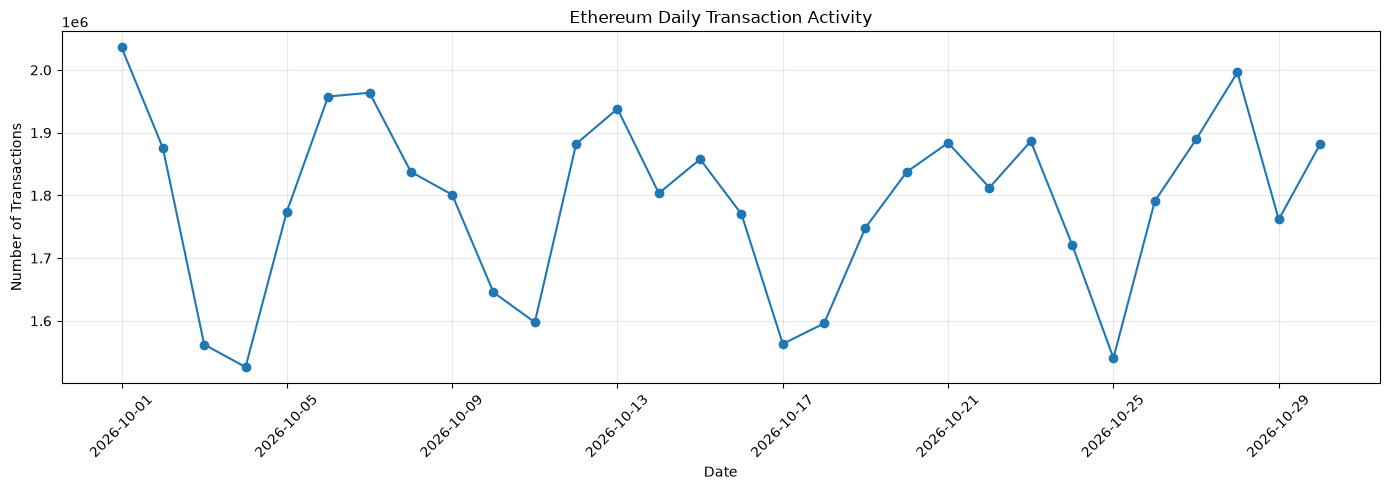

In [19]:
# Daily transaction activity chart
plt.figure(figsize=(14, 5))

plt.plot(
    daily_activity["date"],
    daily_activity["total_transactions"],
    marker="o"
)

plt.title("Ethereum Daily Transaction Activity")
plt.xlabel("Date")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

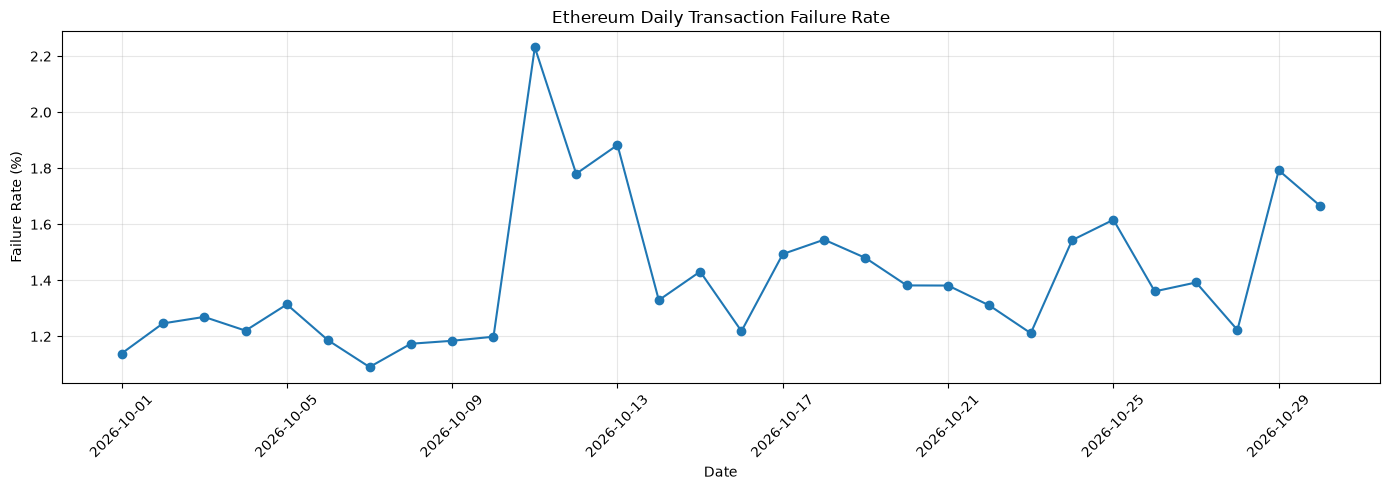

In [20]:
# Daily transaction failure rate
plt.figure(figsize=(14, 5))

plt.plot(
    daily_activity["date"],
    daily_activity["failure_rate_pct"],
    marker="o"
)

plt.title("Ethereum Daily Transaction Failure Rate")
plt.xlabel("Date")
plt.ylabel("Failure Rate (%)")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [21]:
# Identify the exact dates
print("TOP 5 FAILURE-RATE DAYS")

display(
    daily_activity[
        ["date", "total_transactions", "failed_transactions",
         "failure_rate_pct"]
    ]
    .nlargest(5, "failure_rate_pct")
    .round(3)
)

print("BOTTOM 5 FAILURE-RATE DAYS")

display(
    daily_activity[
        ["date", "total_transactions", "failed_transactions",
         "failure_rate_pct"]
    ]
    .nsmallest(5, "failure_rate_pct")
    .round(3)
)

TOP 5 FAILURE-RATE DAYS


C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_4924\3976515427.py:10: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(3)


,date,total_transactions,failed_transactions,failure_rate_pct
10,2026-10-11,1597680,35652,2.231
12,2026-10-13,1938056,36493,1.883
28,2026-10-29,1761646,31579,1.793
11,2026-10-12,1882099,33507,1.780
29,2026-10-30,1881506,31348,1.666


BOTTOM 5 FAILURE-RATE DAYS


C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_4924\3976515427.py:21: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(3)


,date,total_transactions,failed_transactions,failure_rate_pct
6,2026-10-07,1963594,21416,1.091
0,2026-10-01,2036041,23187,1.139
7,2026-10-08,1837570,21569,1.174
8,2026-10-09,1801067,21331,1.184
5,2026-10-06,1957602,23214,1.186


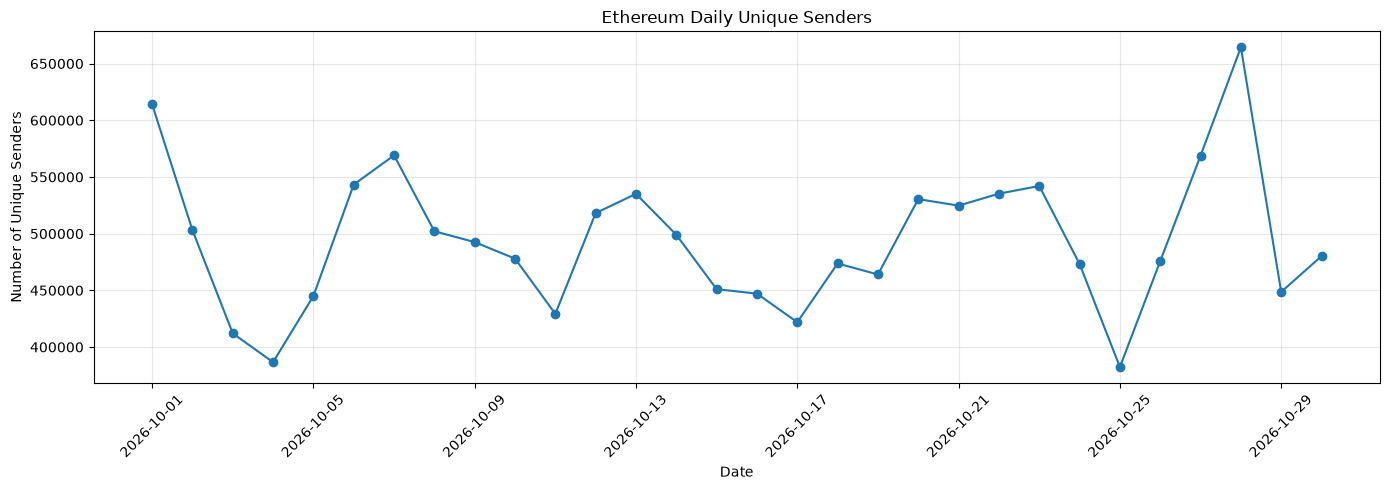

In [22]:
# Daily unique senders
plt.figure(figsize=(14, 5))

plt.plot(
    daily_activity["date"],
    daily_activity["unique_senders"],
    marker="o"
)

plt.title("Ethereum Daily Unique Senders")
plt.xlabel("Date")
plt.ylabel("Number of Unique Senders")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [23]:
print("TOP 5 DAYS — UNIQUE SENDERS")

display(
    daily_activity[
        ["date", "total_transactions", "unique_senders"]
    ].nlargest(5, "unique_senders")
)

print("BOTTOM 5 DAYS — UNIQUE SENDERS")

display(
    daily_activity[
        ["date", "total_transactions", "unique_senders"]
    ].nsmallest(5, "unique_senders")
)

print("\nUNIQUE SENDER STATISTICS")

print("Average:", round(daily_activity["unique_senders"].mean()))
print("Maximum:", daily_activity["unique_senders"].max())
print("Minimum:", daily_activity["unique_senders"].min())

TOP 5 DAYS — UNIQUE SENDERS


,date,total_transactions,unique_senders
27,2026-10-28,1996106,664339
0,2026-10-01,2036041,614194
6,2026-10-07,1963594,569053
26,2026-10-27,1889215,568758
5,2026-10-06,1957602,543286


BOTTOM 5 DAYS — UNIQUE SENDERS


,date,total_transactions,unique_senders
24,2026-10-25,1540685,382357
3,2026-10-04,1526358,386638
2,2026-10-03,1562292,412076
16,2026-10-17,1563246,421868
10,2026-10-11,1597680,429247



UNIQUE SENDER STATISTICS
Average: 493701
Maximum: 664339
Minimum: 382357


In [24]:
# Correlation
# Correlation analysis

correlation = daily_activity[
    [
        "total_transactions",
        "unique_senders",
        "failure_rate_pct"
    ]
].corr()

display(correlation.round(3))

,total_transactions,unique_senders,failure_rate_pct
total_transactions,1.000,0.859,-0.268
unique_senders,0.859,1.000,-0.322
failure_rate_pct,-0.268,-0.322,1.000


In [25]:
# calculate average transactions per sender
daily_activity["transactions_per_sender"] = (
    daily_activity["total_transactions"]
    / daily_activity["unique_senders"]
)

print("Average transactions per sender per day:")

print(
    round(
        daily_activity["transactions_per_sender"].mean(),
        3
    )
)

print("\nHighest transactions per sender:")

display(
    daily_activity.nlargest(
        5, "transactions_per_sender"
    )[
        ["date", "total_transactions",
         "unique_senders", "transactions_per_sender"]
    ].round(3)
)

Average transactions per sender per day:
3.654

Highest transactions per sender:


C:\Users\AL MUZDAHAR COMPUTER\AppData\Local\Temp\ipykernel_4924\7722122.py:24: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(3)


,date,total_transactions,unique_senders,transactions_per_sender
14,2026-10-15,1857648,451032,4.119
24,2026-10-25,1540685,382357,4.029
4,2026-10-05,1774270,445014,3.987
15,2026-10-16,1770145,447103,3.959
3,2026-10-04,1526358,386638,3.948


In [27]:
# Identify unusual days
daily_activity["previous_7d_avg"] = (
    daily_activity["total_transactions"]
    .shift(1)
    .rolling(window=7, min_periods=7)
    .mean()
)

daily_activity["previous_7d_std"] = (
    daily_activity["total_transactions"]
    .shift(1)
    .rolling(window=7, min_periods=7)
    .std()
)

daily_activity["transaction_zscore"] = (
    (daily_activity["total_transactions"]
     - daily_activity["previous_7d_avg"])
    / daily_activity["previous_7d_std"]
)

anomalies = daily_activity[
    daily_activity["transaction_zscore"].abs() >= 2
][
    ["date", "total_transactions",
     "previous_7d_avg", "transaction_zscore"]
].copy()

display(anomalies.round({"total_transactions": 2,
                         "previous_7d_avg": 2,
                         "transaction_zscore": 2}))

,date,total_transactions,previous_7d_avg,transaction_zscore
24,2026-10-25,1540685,1783731.71,-2.34


In [28]:
# investigate October 25
daily_activity.loc[
    daily_activity["date"] == "2026-10-25",
    [
        "date",
        "total_transactions",
        "unique_senders",
        "failure_rate_pct",
        "transactions_per_sender"
    ]
]

,date,total_transactions,unique_senders,failure_rate_pct,transactions_per_sender
24,2026-10-25,1540685,382357,1.616164,4.029441


In [30]:
# compare October 25 with October 28
comparison = daily_activity[
    daily_activity["date"].isin([
        pd.Timestamp("2026-10-25"),
        pd.Timestamp("2026-10-28")
    ])
][
    [
        "date",
        "total_transactions",
        "unique_senders",
        "failure_rate_pct",
        "transactions_per_sender"
    ]
]

display(comparison.to_string(index=False))

'      date  total_transactions  unique_senders  failure_rate_pct  transactions_per_sender\n2026-10-25             1540685          382357          1.616164                 4.029441\n2026-10-28             1996106          664339          1.222981                 3.004650'

In [31]:
# were unique senders also anomalous?
daily_activity["senders_previous_7d_avg"] = (
    daily_activity["unique_senders"]
    .shift(1)
    .rolling(window=7, min_periods=7)
    .mean()
)

daily_activity["senders_previous_7d_std"] = (
    daily_activity["unique_senders"]
    .shift(1)
    .rolling(window=7, min_periods=7)
    .std()
)

daily_activity["sender_zscore"] = (
    (daily_activity["unique_senders"]
     - daily_activity["senders_previous_7d_avg"])
    / daily_activity["senders_previous_7d_std"]
)

display(
    daily_activity[
        daily_activity["sender_zscore"].abs() >= 2
    ][
        ["date", "unique_senders",
         "senders_previous_7d_avg", "sender_zscore"]
    ].round({
        "unique_senders": 2,
        "senders_previous_7d_avg": 2,
        "sender_zscore": 2
    })
)

,date,unique_senders,senders_previous_7d_avg,sender_zscore
24,2026-10-25,382357,506213.43,-3.63
27,2026-10-28,664339,500313.14,2.62


In [32]:
# combine both anomaly signals
daily_activity["transaction_anomaly"] = (
    daily_activity["transaction_zscore"].abs() >= 2
)

daily_activity["sender_anomaly"] = (
    daily_activity["sender_zscore"].abs() >= 2
)

daily_activity["anomaly_type"] = "Normal"

daily_activity.loc[
    daily_activity["transaction_anomaly"] &
    daily_activity["sender_anomaly"],
    "anomaly_type"
] = "Both"

daily_activity.loc[
    daily_activity["transaction_anomaly"] &
    ~daily_activity["sender_anomaly"],
    "anomaly_type"
] = "Transaction only"

daily_activity.loc[
    ~daily_activity["transaction_anomaly"] &
    daily_activity["sender_anomaly"],
    "anomaly_type"
] = "Sender only"

display(
    daily_activity[
        daily_activity["anomaly_type"] != "Normal"
    ][
        [
            "date",
            "total_transactions",
            "unique_senders",
            "transaction_zscore",
            "sender_zscore",
            "anomaly_type"
        ]
    ].round({
        "total_transactions": 0,
        "unique_senders": 0,
        "transaction_zscore": 2,
        "sender_zscore": 2
    })
)

,date,total_transactions,unique_senders,transaction_zscore,sender_zscore,anomaly_type
24,2026-10-25,1540685,382357,-2.34,-3.63,Both
27,2026-10-28,1996106,664339,1.64,2.62,Sender only


In [33]:
# save the anomaly results
anomaly_results = daily_activity[
    daily_activity["anomaly_type"] != "Normal"
][
    [
        "date",
        "total_transactions",
        "unique_senders",
        "failure_rate_pct",
        "transactions_per_sender",
        "transaction_zscore",
        "sender_zscore",
        "anomaly_type"
    ]
].copy()

anomaly_results.to_csv(
    "../CSVs/ethereum_network_activity_anomalies.csv",
    index=False
)

print("Anomaly results exported successfully.")
display(anomaly_results)

Anomaly results exported successfully.


,date,total_transactions,unique_senders,failure_rate_pct,transactions_per_sender,transaction_zscore,sender_zscore,anomaly_type
24,2026-10-25,1540685,382357,1.616164,4.029441,-2.342657,-3.631353,Both
27,2026-10-28,1996106,664339,1.222981,3.004650,1.642226,2.621442,Sender only


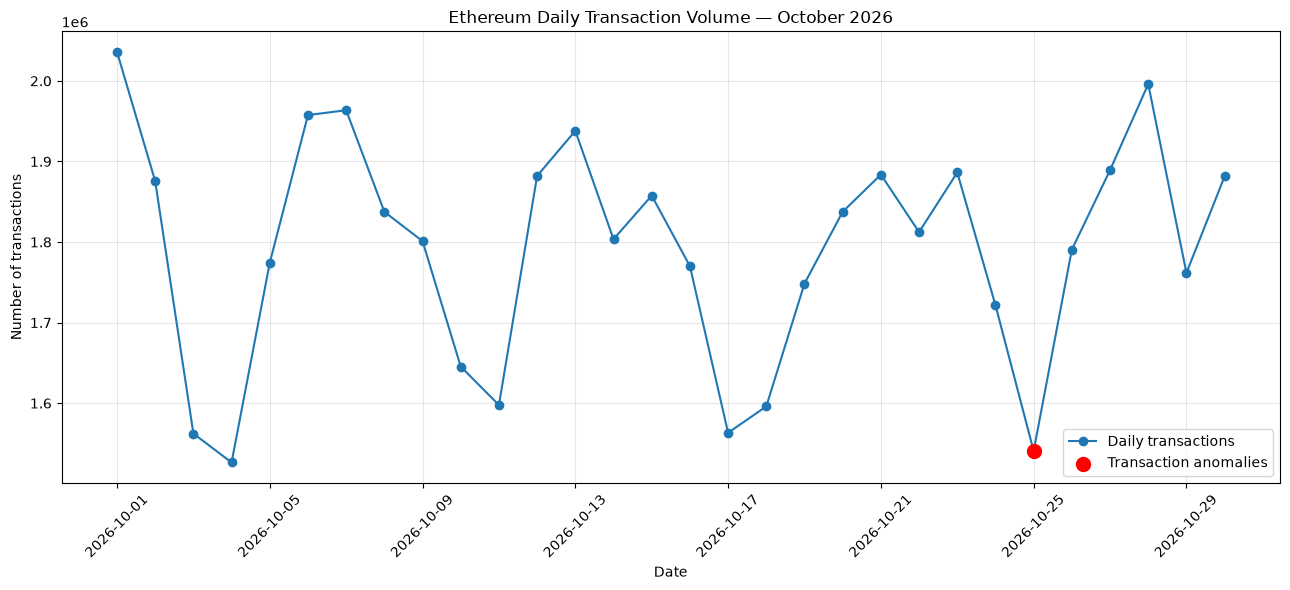

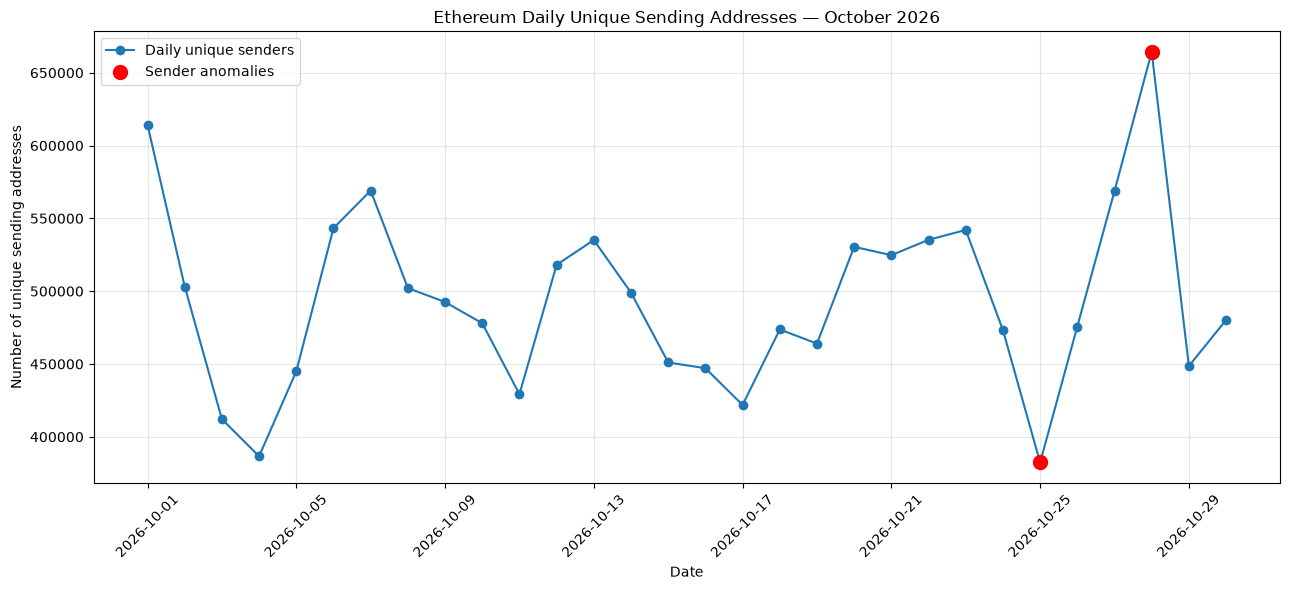

Both anomaly charts saved successfully.


In [34]:
# create two final anomaly charts
import os

os.makedirs("../visualizations", exist_ok=True)

# Chart 1: Transaction volume anomalies
plt.figure(figsize=(13, 6))

plt.plot(
    daily_activity["date"],
    daily_activity["total_transactions"],
    marker="o",
    label="Daily transactions"
)

plt.scatter(
    daily_activity.loc[
        daily_activity["transaction_anomaly"], "date"
    ],
    daily_activity.loc[
        daily_activity["transaction_anomaly"], "total_transactions"
    ],
    color="red",
    s=100,
    label="Transaction anomalies",
    zorder=3
)

plt.title("Ethereum Daily Transaction Volume — October 2026")
plt.xlabel("Date")
plt.ylabel("Number of transactions")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../visualizations/06_transaction_volume_anomalies.png",
    dpi=150
)

plt.show()


# Chart 2: Unique sender anomalies
plt.figure(figsize=(13, 6))

plt.plot(
    daily_activity["date"],
    daily_activity["unique_senders"],
    marker="o",
    label="Daily unique senders"
)

plt.scatter(
    daily_activity.loc[
        daily_activity["sender_anomaly"], "date"
    ],
    daily_activity.loc[
        daily_activity["sender_anomaly"], "unique_senders"
    ],
    color="red",
    s=100,
    label="Sender anomalies",
    zorder=3
)

plt.title("Ethereum Daily Unique Sending Addresses — October 2026")
plt.xlabel("Date")
plt.ylabel("Number of unique sending addresses")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../visualizations/07_unique_sender_anomalies.png",
    dpi=150
)

plt.show()

print("Both anomaly charts saved successfully.")